rows used: 59
missing: 2
count      59.000000
mean     2357.237288
std      1434.174463
min        26.000000
25%      1008.000000
50%      2005.000000
75%      3712.500000
max      4677.000000
Name: loyalty_points, dtype: float64
mean: 2357.237288135593
median: 2005.0
sample SD: 1434.1744632363998
IQR: 2704.5
possible outliers: 0


/tmp/ipykernel_28782/3500219680.py:27: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(s, vert=False)


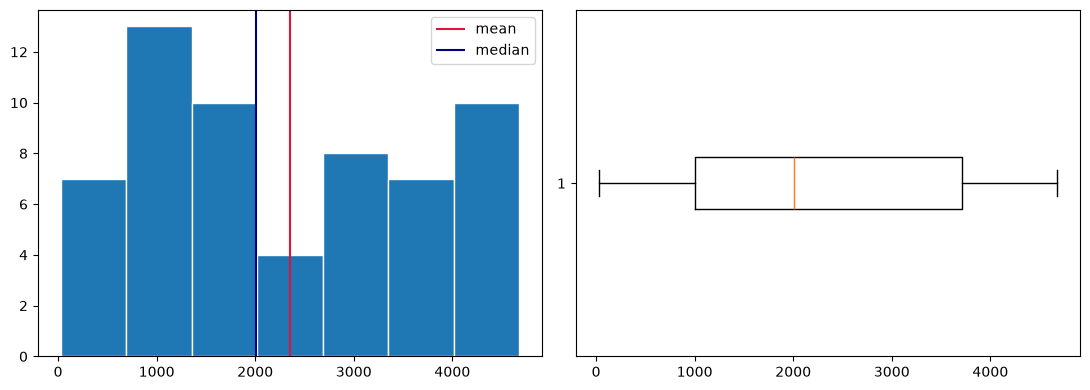

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("customers.csv")

s = pd.to_numeric(df["loyalty_points"], errors="coerce").dropna()

print("rows used:", s.size)
print("missing:", df["loyalty_points"].isna().sum())
print(s.describe(percentiles=[0.25, 0.5, 0.75]))

q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print("mean:", s.mean())
print("median:", s.median())
print("sample SD:", s.std(ddof=1))
print("IQR:", iqr)
print("possible outliers:", ((s < lower) | (s > upper)).sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(s, bins="auto", edgecolor="white")
axes[0].axvline(s.mean(), color="crimson", label="mean")
axes[0].axvline(s.median(), color="navy", label="median")
axes[0].legend()
axes[1].boxplot(s, vert=False)
plt.tight_layout()
plt.show()